[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/htfa_network_animations.ipynb)

# Brain networks of orders 1 to 4 (with HTFA)

This tutorial computes dynamic correlations of orders 1 to 4 with `tc.features` on fMRI data recorded while people listened to a story, and draws each order as a network on the brain over time. You will learn what the features and correlations of each order are, where on the brain each feature sits, and how to turn them into videos with the [htfa](https://htfa.readthedocs.io/en/latest/) toolbox.

**Data.** The intact-story condition of Simony et al. (2016), *Nature Communications* 7, 12141 ([doi:10.1038/ncomms12141](https://doi.org/10.1038/ncomms12141)), as fit with hierarchical topographic factor analysis (HTFA; Manning et al., 2018, *NeuroImage* 180, 243-252, [doi:10.1016/j.neuroimage.2018.01.071](https://doi.org/10.1016/j.neuroimage.2018.01.071)) by Owen, Chang & Manning (2021), *Nature Communications* 12, 5728 ([doi:10.1038/s41467-021-25876-x](https://doi.org/10.1038/s41467-021-25876-x)). HTFA describes each brain image as a weighted sum of 700 nodes (radial basis functions), so each participant's data is a matrix of node weights (timepoints by nodes). The fit is in the data archive of [github.com/ContextLab/timecorr-paper](https://github.com/ContextLab/timecorr-paper).

On its first run, the notebook downloads a 460 MB archive and keeps the fit in `$TIMECORR_DATA` (default `~/timecorr_data`). Rendering the videos takes most of the run time, which the last cell prints (this run used a GPU). On a Colab runtime without a GPU, rendering is slower; that time was not measured.

In [1]:
# On Google Colab, install timecorr (this cell does nothing elsewhere): release 0.3.0 or
# later from PyPI, or the GitHub master branch when PyPI does not have it.
import subprocess
import sys

if "google.colab" in sys.modules:
    def run(command):
        # run a shell command quietly; print its output only if it fails
        result = subprocess.run(command, shell=True, capture_output=True, text=True)
        if result.returncode:
            print(result.stdout + result.stderr)
        return result.returncode == 0

    if run('pip install -q "timecorr[tutorials]>=0.3.0"'):
        print("Installed timecorr from PyPI.")
    elif run('pip install -q "timecorr[tutorials] @ git+https://github.com/ContextLab/timecorr.git@master"'):
        print("Installed timecorr from GitHub master (the PyPI install failed; see above).")
    else:
        raise RuntimeError("timecorr could not be installed; see pip's messages above.")

In [2]:
import base64
import hashlib
import io
import os
import subprocess
import time
import urllib.request
import warnings
import zipfile
from pathlib import Path

import imageio_ffmpeg
import matplotlib.pyplot as plt
import numpy as np
import scipy.io
from IPython.display import HTML, Image, display
from joblib import Parallel, delayed
from joblib.externals.loky import get_reusable_executor
from PIL import Image as PILImage

import htfa
from htfa.brainnet import annotate_pair, effective_nodes, mni_mask, montage, plot_network
import timecorr as tc

%matplotlib inline
NOTEBOOK_START = time.time()
print('timecorr', tc.__version__, '| htfa', htfa.__version__)

timecorr 0.3.0 | htfa 0.1.0


## 1. Download the fit

The cell below downloads the archive once, keeps only the HTFA fit, checks its SHA-256 checksum and deletes the archive.

In [3]:
DATA_DIR = Path(os.environ.get('TIMECORR_DATA', Path.home() / 'timecorr_data')) / 'pieman'
DATA_DIR.mkdir(parents=True, exist_ok=True)
ARCHIVE_URL = ('https://drive.usercontent.google.com/download'
               '?id=1CZYe8eyAkZFuLqfwwlKoeijgkjdW6vFs&export=download&confirm=t')
MEMBER = 'data/pieman_posterior_K700.mat'
FIT_SHA256 = '870179316f127776ff78096c361df6b1c5c7957d6456deb26b5489bcee6c0793'
fit_path = DATA_DIR / 'pieman_posterior_K700.mat'


def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()


if not fit_path.exists():
    archive = DATA_DIR / 'data.zip'
    urllib.request.urlretrieve(ARCHIVE_URL, archive)
    with zipfile.ZipFile(archive) as z, z.open(MEMBER) as src, open(fit_path, 'wb') as dst:
        while chunk := src.read(1 << 20):
            dst.write(chunk)
    archive.unlink()
if sha256(fit_path) != FIT_SHA256:
    raise RuntimeError(f'{fit_path.name} does not match its checksum; delete it and run this cell again')
print(fit_path.name, f'{fit_path.stat().st_size / 1e6:.0f} MB')

pieman_posterior_K700.mat 233 MB


## 2. Choose the nodes

The fit is a MATLAB file, read here with `scipy.io.loadmat`. The notebook analyzes 100 of the 700 nodes, which keeps the run short: among the nodes whose weights vary over time in every participant, it picks them by farthest-point sampling of the node centers (start at the node nearest the middle of all centers, then repeatedly add the node farthest from those already chosen), which spreads them over the brain. Every figure and video below shows these nodes, each drawn at the part of its radial basis function that lies inside an MNI brain mask (`htfa.brainnet.effective_nodes`).

36 participants, 300 timepoints; 679 of 700 nodes vary in every participant; analyzing 100


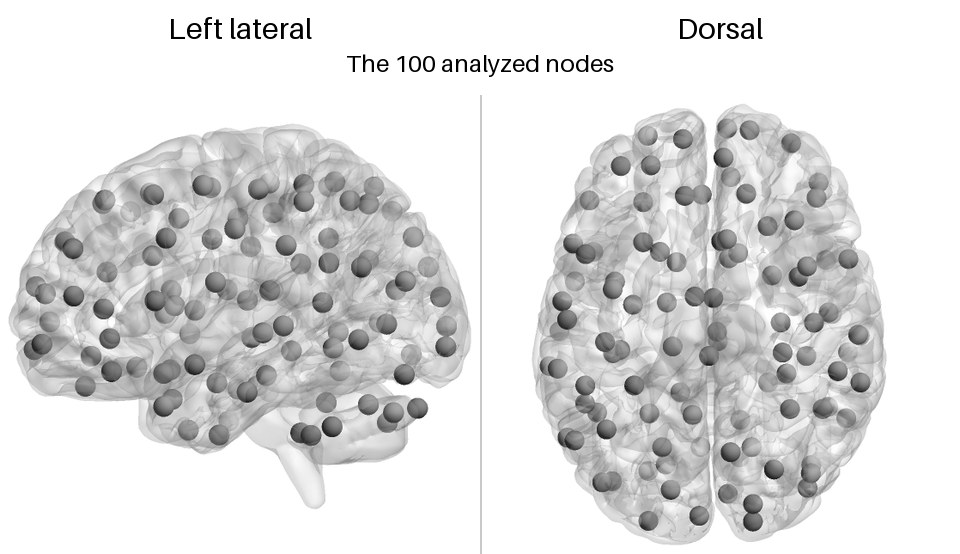

In [4]:
post = scipy.io.loadmat(fit_path)['posterior'][0, 0]
names = [str(n[0]) for n in post['subjects_names'][0]]
centers = np.asarray(post['centers'][0, 0]['mean'], dtype=float)        # template centers (MNI mm)
widths = np.asarray(post['widths'][0, 0]['mean'], dtype=float).ravel()
intact = sorted((i for i, n in enumerate(names) if n.startswith('intact_')),
                key=lambda i: int(names[i].split('_s')[1].split('.')[0]))
weights = np.stack([post['subjects'][0, i]['image_weights'][0, 0]['mean'][0, 0] for i in intact])
del post
n_participants, T, n_nodes = weights.shape
varying = np.flatnonzero((weights.std(axis=1) > 1e-6).all(axis=0))


def farthest_points(points, k):
    chosen = [int(np.argmin(np.linalg.norm(points - points.mean(axis=0), axis=1)))]
    dist = np.linalg.norm(points - points[chosen[0]], axis=1)
    for _ in range(k - 1):
        chosen.append(int(np.argmax(dist)))
        dist = np.minimum(dist, np.linalg.norm(points - points[chosen[-1]], axis=1))
    return np.array(chosen)


K = 100
nodes = varying[farthest_points(centers[varying], K)]
data = [w[:, nodes] for w in weights]           # one (timepoints, K) matrix per participant
xyz, _, _ = effective_nodes(centers[nodes], widths[nodes], mni_mask())
print(f'{n_participants} participants, {T} timepoints; {len(varying)} of {n_nodes} nodes '
      f'vary in every participant; analyzing {K}')

VIEWS = ('left', 'dorsal')
VIEW_TITLES = ('Left lateral', 'Dorsal')


def show_image(img, width=None):
    # display a PIL image as a JPEG
    if width is not None and img.width > width:
        img = img.resize((width, round(img.height * width / img.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    img.convert('RGB').save(buf, format='JPEG', quality=88)
    display(Image(data=buf.getvalue(), format='jpeg'))


show_image(annotate_pair(*[plot_network(xyz, snap=False, size=(880, 550), view=v) for v in VIEWS],
                         VIEW_TITLES, caption=f'The {K} analyzed nodes', width=960))

## 3. Features of orders 1 to 4

For each order `k`, `tc.features` computes two things (see the [higher-order tutorial](higher_order.ipynb) and [tc.features](../generated/timecorr.features.rst)):

- `X[k]`, the order-`k` features: dynamic correlations between the columns of `D[k-1]`, computed across participants with `tc.isfc` and summarized with PCA at order 1 and with `tc.WeightedStrength(signed=True)` above (one magnitude and one signed column per input column);
- `D[k]`, the columns that feed order `k + 1`: within-participant dynamic correlations of `D[k-1]`, summarized with `tc.Communities()` (one column per community of columns), or with one column per input column when the communities give too few columns.

`D[0]` is the node weights. `return_delta=True` also returns `D`, and `return_info=True` returns a record of each step, printed below.

In [5]:
start = time.time()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    (X, D), info = tc.features(data, order=4, return_delta=True, return_info=True)
print(f'tc.features: {time.time() - start:.0f} s')
for w in caught:
    print(f'{w.category.__name__}: {w.message}')
print()
print(f'{"order":>5} {"path":>9} {"input":>6} {"output":>7}  summary used')
for step in info:
    used = step['effective'].split('(')[0]
    if step.get('fallback'):
        used += f' (communities gave {step["n_communities"]} column(s): {step["fallback"]})'
    print(f'{step["order"]:>5} {step["path"]:>9} {step["input_width"]:>6} {step["output_width"]:>7}  {used}')

tc.features: 37 s

order      path  input  output  summary used
    1  analysis    100     100  PCA
    1   feeding    100     100  WeightedStrength (communities gave 2 column(s): too_few_community_columns)
    2  analysis    100     200  WeightedStrength
    2   feeding    100       4  Communities
    3  analysis      4       8  WeightedStrength
    3   feeding      4       4  WeightedStrength (communities gave 1 column(s): too_few_community_columns)
    4  analysis      4       8  WeightedStrength
    4   feeding      4       4  WeightedStrength (communities gave 1 column(s): too_few_community_columns)


The table shows which summary each feeding step used. The warnings report summary columns that are constant over time; `tc.features` sets them to their means.

## 4. Where each feature sits on the brain

Each column of `D[k]` belongs to a set of nodes. A column of `D[0]` is one node. A step that keeps one column per input column keeps the input's node sets, and a community column belongs to the union of its members' sets (a community of one member emits no column). `tc.features` does not return the memberships found by its default reducer, so the cell below repeats the run with an explicit `tc.Communities()` at the steps that used communities, checks that the outputs are the same, and reads the memberships from its `fits_`. Each feature is placed at the centroid of its nodes.

In [6]:
community_orders = [s['order'] for s in info
                    if s['path'] == 'feeding' and s['effective'].startswith('Communities')]
explicit = {k: tc.Communities() for k in community_orders}
with warnings.catch_warnings(record=True) as caught_again:
    warnings.simplefilter('always')
    X_check, D_check = tc.features(data, order=4, return_delta=True, delta_rfun=explicit or 'auto')
same = all(np.array_equal(a, b) for out, check in ((X, X_check), (D, D_check))
           for k in range(5) for a, b in zip(out[k], check[k]))
assert same, 'the explicit Communities() run differs from the default run'
print(f'explicit Communities() at orders {community_orders}: outputs equal to the default run;',
      'same warnings' if [str(w.message) for w in caught_again] == [str(w.message) for w in caught]
      else 'different warnings')

# node_sets[k][i]: the analyzed nodes (indices into xyz) that column i of D[k] belongs to
node_sets = {0: [np.array([i]) for i in range(K)]}
for step in (s for s in info if s['path'] == 'feeding'):
    k, prev = step['order'], node_sets[step['order'] - 1]
    if k in explicit:
        labels = explicit[k].fits_[-1]['labels']
        groups = [np.flatnonzero(labels == g) for g in np.unique(labels)]
        groups = sorted((g for g in groups if len(g) >= 2), key=lambda g: g.min())
        node_sets[k] = [np.concatenate([prev[j] for j in g]) for g in groups]
    else:
        node_sets[k] = prev
    assert len(node_sets[k]) == step['output_width']   # one set per column of D[k]
    sets = node_sets[k]
    sizes = ', '.join(str(len(s)) for s in sets) if len(sets) <= 10 else f'{sorted({len(s) for s in sets})}'
    print(f'D[{k}]: {len(sets)} columns; nodes per column: {sizes}')
positions = {k: np.array([xyz[s].mean(axis=0) for s in sets]) for k, sets in node_sets.items()}

explicit Communities() at orders [2]: outputs equal to the default run; same warnings
D[1]: 100 columns; nodes per column: [1]
D[2]: 4 columns; nodes per column: 22, 36, 16, 26
D[3]: 4 columns; nodes per column: 22, 36, 16, 26
D[4]: 4 columns; nodes per column: 22, 36, 16, 26


The cell below defines how features are drawn: when the features of an order are communities, each community gets its own color, used for its member nodes and for the sphere at its centroid. The colors come from colorblind-safe palettes without red or blue, which mark the signs of edges. It then draws the communities. The second view is dorsal, or posterior when that separates the community centroids better.

order 1: 100 features (single nodes); views: left lateral, dorsal
order 2: 100 features (single nodes); views: left lateral, dorsal
order 3: 4 features (communities); views: left lateral, dorsal
order 4: 4 features (communities); views: left lateral, dorsal


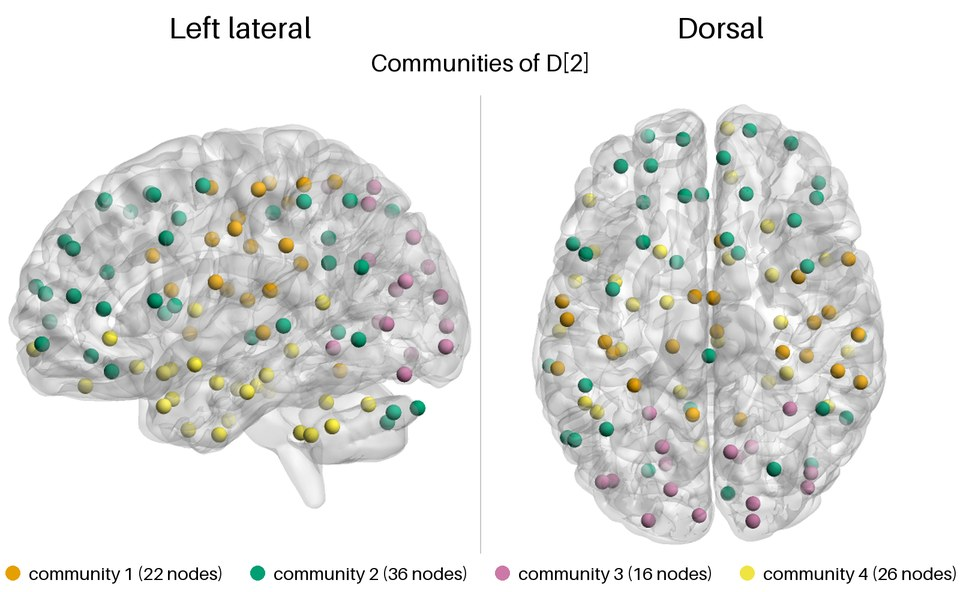

In [7]:
import pyvista as pv
from htfa.brainnet import VIEWS as VIEW_DIRECTIONS, load_mesh
from matplotlib.colors import to_hex
from htfa.brainnet import _Scene   # htfa's renderer; plot_network draws every node in one color
from PIL import ImageDraw, ImageFont

GRAY = '#808080'
# Okabe-Ito and Paul Tol colors without red or blue (red and blue mark edge signs)
PALETTE = ['#E69F00', '#009E73', '#CC79A7', '#F0E442', '#000000', '#999933', '#44AA99', '#DDCC77']
VIEW_NAMES = {'left': 'Left lateral', 'dorsal': 'Dorsal', 'posterior': 'Posterior'}


def group_colors(n):
    # n distinct colors (Tableau colors after the first 8)
    extra = [to_hex(c) for c in plt.cm.tab20b(np.linspace(0, 1, max(n - len(PALETTE), 1)))]
    return (PALETTE + extra)[:n]


def draw_view(nodes_xyz, radii, colors, view, size, edges=None):
    # one view of the brain: spheres of the given radii (mm) and colors, and edges
    # (upper triangle; red positive, blue negative, diameter |value| mm)
    scene = _Scene(nodes_xyz, radii, load_mesh('ch2'), view=view, size=size, node_color=GRAY,
                   mesh_color=(0.95, 0.95, 0.95), mesh_opacity=0.2, background='white',
                   node_opacity=np.zeros(len(radii)), radius_kb=(1.0, 0.0))
    try:
        for color in dict.fromkeys(colors):
            spheres = [pv.Sphere(radius=r, center=c, theta_resolution=40, phi_resolution=40)
                       for c, r, col in zip(nodes_xyz, radii, colors) if col == color]
            scene.pl.add_mesh(pv.merge(spheres), color=color, smooth_shading=True,
                              ambient=0.3, diffuse=0.8, specular=0.0)
        if edges is not None:
            scene.set_edges(edges, threshold=0.0, edge_style='intensity',
                            positive_color='red', negative_color='blue')
        return scene.image()
    finally:
        scene.close()


def legend_band(items, width, height=64, fontsize=30):
    # a white strip with (color, text, 'line' or 'dot') entries, centered
    band = PILImage.new('RGB', (width, height), 'white')
    draw = ImageDraw.Draw(band)
    font = ImageFont.load_default(size=fontsize)
    gap, mark = 40, 34
    total = sum(mark + 10 + draw.textlength(text, font=font) for _, text, _ in items) + gap * (len(items) - 1)
    x, y = (width - total) / 2, height / 2
    for color, text, kind in items:
        if kind == 'line':
            draw.line([(x, y), (x + mark, y)], fill=color, width=6)
        else:
            draw.ellipse([x + 5, y - 12, x + 29, y + 12], fill=color)
        x += mark + 10
        draw.text((x, y), text, font=font, fill='black', anchor='lm')
        x += draw.textlength(text, font=font) + gap
    return band


# drawing of the features of each order k (columns of D[k-1]); the number of groups is
# the width of the feeding step that made D[k-1], read from return_info
widths_D = {0: K} | {s['order']: s['output_width'] for s in info if s['path'] == 'feeding'}
features_of = {}
for k in range(1, 5):
    sets = node_sets[k - 1]
    assert len(sets) == widths_D[k - 1]
    grouped = any(len(s) > 1 for s in sets)
    colors = group_colors(len(sets)) if grouped else [GRAY] * len(sets)
    node_colors = [GRAY] * K                      # nodes in no group stay gray
    for s, c in zip(sets, colors):
        for i in s:
            node_colors[i] = c
    second = 'dorsal'
    if grouped:
        def separation(view):
            d = np.asarray(VIEW_DIRECTIONS[view][0])
            p = positions[k - 1] - np.outer(positions[k - 1] @ d, d)   # projected centroids
            return min((np.linalg.norm(a - b) for n, a in enumerate(p) for b in p[n + 1:]), default=np.inf)
        second = max(('dorsal', 'posterior'), key=separation)
    legend = [(c, f'community {g + 1} ({len(s)} nodes)', 'dot') for g, (s, c) in enumerate(zip(sets, colors))]
    features_of[k] = dict(grouped=grouped, colors=colors, node_colors=node_colors,
                          views=('left', second), legend=legend if grouped else [])
    print(f'order {k}: {len(sets)} features ({"communities" if grouped else "single nodes"}); '
          f'views: left lateral, {second}')

for k in community_orders:
    f = features_of[k + 1]                       # the order whose features are these communities
    radii = np.full(K, 3.0)
    views = [draw_view(xyz, radii, f['node_colors'], v, (880, 550)) for v in f['views']]
    pair = annotate_pair(*views, tuple(VIEW_NAMES[v] for v in f['views']),
                         caption=f'Communities of D[{k}]', width=1600)
    band = legend_band(f['legend'], pair.width)
    figure = PILImage.new('RGB', (pair.width, pair.height + band.height), 'white')
    figure.paste(pair, (0, 0))
    figure.paste(band, (0, pair.height))
    show_image(figure, width=960)

## 5. Correlations of each order

An order-`k` correlation is a dynamic correlation between two columns of `D[k-1]`, that is, between two order-`(k-1)` features. The cell below computes them with `tc.timecorr` (the kernel and `cfun` that `tc.features` uses), checks that summarizing them as `tc.features` does gives `X[k]` again, and averages them over participants with `tc.corrmean_combine`.

In [8]:
R, values, messages = {}, {}, []
for k in range(1, 5):
    corrs = tc.timecorr(D[k - 1], cfun=tc.isfc, combine=tc.null_combine)
    summary = 'PCA' if k == 1 else tc.WeightedStrength(signed=True)
    step = next(s for s in info if s['order'] == k and s['path'] == 'analysis')
    assert step['effective'] == (summary if k == 1 else repr(summary))
    with warnings.catch_warnings(record=True) as caught_reduce:
        warnings.simplefilter('always')
        again = tc.reduce(corrs, rfun=summary)
    messages += [str(w.message) for w in caught_reduce]
    assert all(np.allclose(a, b, rtol=1e-8, atol=1e-8 * np.abs(b).max()) for a, b in zip(again, X[k]))
    R[k] = tc.vec2mat(tc.corrmean_combine(corrs))            # (features, features, timepoints)
    del corrs, again
    n = R[k].shape[0]
    if k >= 2:
        values[k] = np.mean([x[:, :n] for x in X[k]], axis=0)   # magnitude columns: (timepoints, n)
    print(f'order {k}: correlations between the {n} columns of D[{k - 1}] reproduce X[{k}]')
print('warnings of the summaries:', 'the same as in tc.features' if messages == [str(w.message) for w in caught]
      else messages)

order 1: correlations between the 100 columns of D[0] reproduce X[1]
order 2: correlations between the 100 columns of D[1] reproduce X[2]
order 3: correlations between the 4 columns of D[2] reproduce X[3]
order 4: correlations between the 4 columns of D[3] reproduce X[4]
warnings of the summaries: the same as in tc.features


## 6. Videos

Each video has one frame per timepoint, at 30 frames per second (1920 x 1080, H.264), with a left lateral view and the second view chosen above. At order `k`:

- **edges** join two order-`(k-1)` features and show their order-`k` correlation at that timepoint, averaged over participants: the 50 strongest (all of them when there are fewer pairs), red for positive and blue for negative. The diameter is proportional to `|r|`, scaled in each video so that the median drawn edge is 1.5 mm wide (at most 5 mm);
- **spheres** are the order-`(k-1)` features, at the centroid of their nodes. At orders 2 to 4, a sphere's size shows the feature's magnitude column of `X[k]`, averaged over participants and scaled within each frame (radius 2 to 7 mm for single nodes, 4 to 9 mm for communities), so sizes compare features at one timepoint; the plot after the videos shows the values over time. At order 1 the features are the nodes, drawn at one size, because the PCA components of `X[1]` have no location;
- when the features are communities, each community's sphere and its member nodes (small dots) share the community's color, named in the legend below the brains with the community's number of nodes; nodes in no community are gray.

The cell below defines the drawing and encoding. Frames are rendered in parallel (up to 3 workers, each with its own off-screen window; on Linux without a display, htfa renders off screen with EGL) and encoded with the ffmpeg binary of `imageio-ffmpeg` (CRF 23, with `+faststart` so that browsers start playing early). In the documentation, the videos are saved in `docs/_static/tutorial_media/` and linked; anywhere else (for example on Colab), they are saved in a `htfa_videos` folder and shown inline. Rendering without a GPU is slower: setting `FRAME_STEP = 2` draws every second timepoint and halves the run time and the videos' length.

In [9]:
FRAME_STEP = 1                                  # draw every FRAME_STEP-th timepoint
# in the documentation tree (docs/tutorial), save the videos in docs/_static/tutorial_media
IN_DOCS = Path.cwd().name == 'tutorial' and (Path.cwd().parent / 'conf.py').exists()
MEDIA_DIR = Path('..') / '_static' / 'tutorial_media' if IN_DOCS else Path('htfa_videos')
MEDIA_DIR.mkdir(parents=True, exist_ok=True)
FPS = 30
FRAME_SIZE = (1920, 1080)
VIEW_SIZE = (1200, 750)                         # size of each rendered view, in pixels
CRF = 23                                        # H.264 constant rate factor
N_JOBS = min(3, os.cpu_count() or 1)
TOP_EDGES = 50
MAX_EDGE = 5.0                                  # mm


def strongest(k, t):
    # indices (i, j) and correlations r of the edges drawn at order k, timepoint t
    i, j = np.triu_indices(R[k].shape[0], 1)
    r = R[k][i, j, t]
    keep = np.argsort(-np.abs(r))[:TOP_EDGES]
    return i[keep], j[keep], r[keep]


# edge diameter (mm) per unit |r|: the median drawn edge of each video is 1.5 mm wide
edge_scale = {k: 1.5 / np.median(np.concatenate([np.abs(strongest(k, t)[2]) for t in range(T)]))
              for k in range(1, 5)}
print('edge diameter (mm) per unit |r|:', {k: round(float(v), 1) for k, v in edge_scale.items()})


def rescale(v, lo, hi):
    # map v linearly onto [lo, hi] (the middle when all values are equal)
    span = v.max() - v.min()
    return np.full(len(v), (lo + hi) / 2) if span == 0 else lo + (hi - lo) * (v - v.min()) / span


def scene(k, t):
    # what frame t of order k draws: nodes (m, 3), radii (m,), colors (m,), edges (m, m)
    f = features_of[k]
    P = positions[k - 1]
    n = len(P)
    if k == 1:
        radii = np.full(n, 3.0)
    else:
        radii = rescale(values[k][t], *((4.0, 9.0) if f['grouped'] else (2.0, 7.0)))
    i, j, r = strongest(k, t)
    E = np.zeros((n, n))
    E[i, j] = np.sign(r) * np.minimum(edge_scale[k] * np.abs(r), MAX_EDGE)
    if not f['grouped']:
        return P, radii, f['colors'], E
    edges = np.zeros((K + n, K + n))            # the analyzed nodes, then the features
    edges[K:, K:] = E
    return (np.vstack([xyz, P]), np.concatenate([np.full(K, 1.2), radii]),
            f['node_colors'] + f['colors'], edges)


EDGE_KEY = [('red', 'positive correlation', 'line'), ('blue', 'negative correlation', 'line')]


def content_box(images, margin=24):
    # the smallest box holding every non-white pixel of the images, plus a margin
    mask = np.zeros(images[0].size[::-1], dtype=bool)
    for im in images:
        mask |= np.asarray(im.convert('RGB')).min(axis=2) < 250
    rows, cols = np.flatnonzero(mask.any(axis=1)), np.flatnonzero(mask.any(axis=0))
    w, h = images[0].size
    return (max(0, cols[0] - margin), max(0, rows[0] - margin),
            min(w, cols[-1] + 1 + margin), min(h, rows[-1] + 1 + margin))


# one crop for every frame and view, so that the brain does not move
CROP = content_box([draw_view(xyz, np.full(K, 7.0), [GRAY] * K, v, VIEW_SIZE) for v in VIEW_NAMES])
LEGEND_HEIGHT = 2 * 64                          # two rows: edge signs, then communities


def draw_frame(path, caption, k, nodes_xyz, radii, colors, edges):
    f = features_of[k]
    views = [draw_view(nodes_xyz, radii, colors, v, VIEW_SIZE, edges) for v in f['views']]
    for v in views:
        # an off-screen window that ran out of GPU memory returns a black image
        if (np.asarray(v.convert('RGB')).max(axis=2) < 10).mean() > 0.05:
            raise RuntimeError('a view was rendered black')
    im = annotate_pair(*views, tuple(VIEW_NAMES[v] for v in f['views']), caption=caption,
                       width=FRAME_SIZE[0], crop=CROP)
    im.thumbnail((FRAME_SIZE[0], FRAME_SIZE[1] - LEGEND_HEIGHT), PILImage.LANCZOS)
    canvas = PILImage.new('RGB', FRAME_SIZE, 'white')
    canvas.paste(im, ((FRAME_SIZE[0] - im.width) // 2, 0))
    canvas.paste(legend_band(EDGE_KEY, FRAME_SIZE[0]), (0, FRAME_SIZE[1] - LEGEND_HEIGHT))
    if f['legend']:
        canvas.paste(legend_band(f['legend'], FRAME_SIZE[0]), (0, FRAME_SIZE[1] - LEGEND_HEIGHT // 2))
    tmp = path.with_suffix('.tmp.png')
    canvas.save(tmp)
    tmp.replace(path)                           # a frame file exists only once it is complete
    return canvas


def caption(k, t):
    return f'Order {k} | timepoint {t + 1} of {T}'


def render(k):
    frames_dir = DATA_DIR / 'frames' / f'order{k}'
    frames_dir.mkdir(parents=True, exist_ok=True)
    for old in frames_dir.glob('*.png'):
        old.unlink()
    start = time.time()
    restarts = 0
    timepoints = range(0, T, FRAME_STEP)
    while todo := [(i, t) for i, t in enumerate(timepoints)
                   if not (frames_dir / f'{i:05d}.png').exists()]:
        try:
            with warnings.catch_warnings():
                # loky replaces worker processes whose memory grows and says so in a UserWarning
                warnings.filterwarnings('ignore', message='A worker stopped')
                Parallel(n_jobs=N_JOBS)(delayed(draw_frame)(frames_dir / f'{i:05d}.png',
                                                            caption(k, t), k, *scene(k, t))
                                        for i, t in todo)
        except Exception:
            # an off-screen window can fail or return a black image when GPU memory runs
            # short; new workers draw the frames not yet written
            restarts += 1
            if restarts > 50:
                raise
            get_reusable_executor().shutdown(wait=True, kill_workers=True)
    path = MEDIA_DIR / f'htfa_order{k}.mp4'
    subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), '-y', '-loglevel', 'error',
                    '-framerate', str(FPS), '-i', str(frames_dir / '%05d.png'),
                    '-c:v', 'libx264', '-preset', 'slow', '-crf', str(CRF),
                    '-pix_fmt', 'yuv420p', '-movflags', '+faststart', str(path)], check=True)
    for frame in frames_dir.glob('*.png'):
        frame.unlink()
    n = len(timepoints)
    print(f'order {k}: {n} frames at {FPS} fps ({n / FPS:.1f} s), rendered in {time.time() - start:.0f} s; '
          f'{path.name}: {path.stat().st_size / 1e6:.1f} MB')
    return path


def show(path):
    # link the file in the documentation; elsewhere, embed it in the output
    if IN_DOCS:
        src = Path(os.path.relpath(path)).as_posix()
    else:
        src = 'data:video/mp4;base64,' + base64.b64encode(path.read_bytes()).decode()
    display(HTML(f'<video src="{src}" controls loop muted playsinline preload="metadata" '
                 f'style="width: 100%; max-width: 960px;"></video>'))

edge diameter (mm) per unit |r|: {1: 6.5, 2: 5.9, 3: 14.6, 4: 13.8}


One frame of the order-2 video, in the middle of the recording:

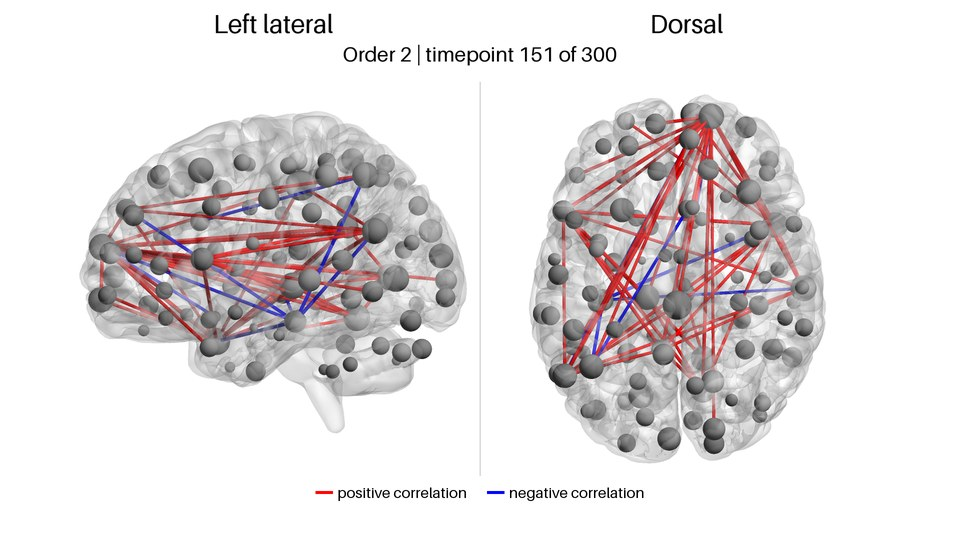

In [10]:
t = T // 2
show_image(draw_frame(DATA_DIR / 'still.png', caption(2, t), 2, *scene(2, t)), width=960)

The four videos (orders 1 to 4):

In [11]:
for k in range(1, 5):
    show(render(k))

order 1: 300 frames at 30 fps (10.0 s), rendered in 251 s; htfa_order1.mp4: 3.1 MB


order 2: 300 frames at 30 fps (10.0 s), rendered in 265 s; htfa_order2.mp4: 4.1 MB


order 3: 300 frames at 30 fps (10.0 s), rendered in 281 s; htfa_order3.mp4: 0.7 MB


order 4: 300 frames at 30 fps (10.0 s), rendered in 266 s; htfa_order4.mp4: 0.7 MB


## 7. Values over time

The left panel shows the mean `|r|` over all pairs of features at each order, and the right panel the mean drawn value of the features of orders 2 to 4, each divided by its largest value. Near the start and the end of the recording, the kernels are cut off by the edges of the recording.

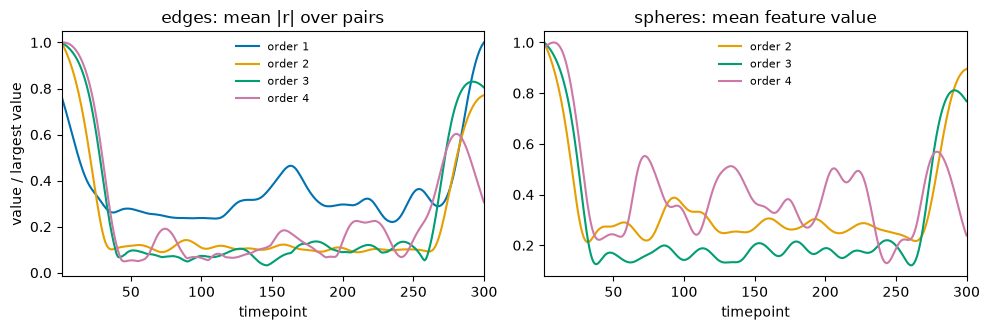

In [12]:
COLORS = ['#0072B2', '#E69F00', '#009E73', '#CC79A7']   # Okabe-Ito
time_axis = np.arange(1, T + 1)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True)
for k in range(1, 5):
    i, j = np.triu_indices(R[k].shape[0], 1)
    mean_r = np.abs(R[k][i, j, :]).mean(axis=0)
    left.plot(time_axis, mean_r / mean_r.max(), color=COLORS[k - 1], label=f'order {k}')
for k in range(2, 5):
    mean_value = values[k].mean(axis=1)
    right.plot(time_axis, mean_value / mean_value.max(), color=COLORS[k - 1], label=f'order {k}')
left.set_title('edges: mean |r| over pairs')
right.set_title('spheres: mean feature value')
for ax in (left, right):
    ax.set_xlabel('timepoint')
    ax.set_xlim(1, T)
    ax.legend(fontsize=8, frameon=False)
left.set_ylabel('value / largest value')
plt.tight_layout()
plt.show()

The picture on this tutorial's card in the gallery: the left lateral view of the order-2 network in the middle of the recording.

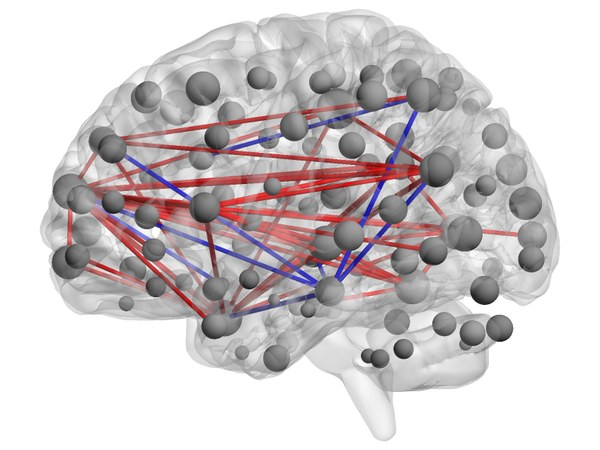

In [13]:
points, radii, colors, edge_matrix = scene(2, T // 2)
view = draw_view(points, radii, colors, 'left', VIEW_SIZE, edge_matrix)
view = view.crop(content_box([view], margin=12))
width = max(view.width, round(view.height * 4 / 3))   # a white 4:3 canvas around it
card = PILImage.new('RGB', (width, round(width * 3 / 4)), 'white')
card.paste(view, ((card.width - view.width) // 2, (card.height - view.height) // 2))
show_image(card, width=600)

In [14]:
print(f'total run time: {(time.time() - NOTEBOOK_START) / 60:.0f} min')

total run time: 20 min
